# Step 1 - Voice Activity Detection (VAD)

**Goal:** read WAV files, extract time-aligned features, identify speech/non-speech intervals, visualize the result, and save reusable features and timestamps for later pipeline steps.

**Method:** use a **pretrained Silero VAD** for speech classification (no training data required). A simple energy threshold alone cannot reliably distinguish speech from music or noise. Silero is more speech-specific, but can still make mistakes with music or overlapping sounds. **A CNN-BiLSTM is not needed for this first implementation**: training one requires annotated speech/non-speech data and evaluation.

Input directory defaults to the existing `INPUT_ROOT` variable; edit it if your files are elsewhere. The following cells do not depend on the earlier example file (`other/harvard.wav`).

In [10]:
from pathlib import Path
from silero_vad import load_silero_vad, get_speech_timestamps
import json
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
import librosa, librosa.feature, librosa.display
import IPython.display as ipd

SAMPLE_RATE = 16000  # supported by Silero VAD
HOP_LENGTH = 160  # 10 ms per frame
N_FFT = 400  # 25 ms analysis window
N_MELS = 20  # number of mel bands to generate
N_MFCC = 20  # number of mfcc to return

OUTPUT_DIR = Path("data/processed/vad")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model = load_silero_vad()

# test file
INPUT_ROOT = Path("data/audio/Female/PTDB-TUG")
EXAMPLE_WAV_FILE = Path("other/harvard.wav")
EXAMPLE_MP3_FILE = Path("other/jill.mp3")

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


$$
\frac{18.35}{0.01}= 1834 \space\text{samples}
$$

## 1. Load audio and extract frame-level features

`librosa.load` converts input to mono and resamples to 16 kHz. MFCCs, RMS energy and log-mel spectrograms are **2D arrays indexed by frame**; unlike the earlier mean-MFCC vector, these retain timing information. Frame `i` corresponds approximately to `i = hop_length / sample_rate` seconds. We use `center=False` for explicit window alignment.

In [11]:
# Load file and extract features
def load_and_extract(path):
    # converts to mono and resamples to 16 kHz. (y=samples)
    y, sr = librosa.load(path, sr=SAMPLE_RATE, mono=True)
    if len(y) < N_FFT:
        y = np.pad(y, (0, N_FFT - len(y)))

    # compute mel spectrogram (returns 2D array Hz & time)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS, center=False)

    # convert to decibel
    log_mel = librosa.power_to_db(mel, ref=np.max)

    # calculated 20 mfc-coefficients
    mfcc = librosa.feature.mfcc(S=log_mel, n_mfcc=N_MFCC)

    # compute rms value for each frame
    rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP_LENGTH, center=False)[0]

    # convert frame counts to time
    times = librosa.frames_to_time(np.arange(mfcc.shape[1]), sr=sr, hop_length=HOP_LENGTH)
    return y, sr, {"mfcc": mfcc, "log_mel": log_mel, "rms": rms, "times": times}

## 2. Detect speech boundaries

The pretrained model outputs speech timestamps in **samples**, which we convert to seconds. Short silences may be retained inside a speech region via `min_silence_duration_ms`. Non-speech is the complement of speech intervals. The output also retains original timestamps so later speaker-diarization steps can refer to the original recording.

In [12]:
def detect_regions(y, sr):
    import torch
    # Silero requires 16 kHz or 8 kHz mono input.
    speech = get_speech_timestamps(torch.from_numpy(y.astype(np.float32)), model,
                                   sampling_rate=sr, return_seconds=False,
                                   min_speech_duration_ms=250,
                                   min_silence_duration_ms=200,
                                   speech_pad_ms=100)
    speech_intervals = [(int(s["start"]), int(s["end"])) for s in speech]
    nonspeech_intervals = []
    prev = 0
    for start, end in speech_intervals:
        if start > prev:
            nonspeech_intervals.append((prev, start))
        prev = max(prev, end)
    if prev < len(y):
        nonspeech_intervals.append((prev, len(y)))
    return speech_intervals, nonspeech_intervals

def to_seconds(intervals, sr):
    return [[round(a / sr, 3), round(b / sr, 3)] for a, b in intervals]

## 3. Visualize waveform, spectrogram and speech/non-speech

Green regions are classified as speech; gray regions are non-speech. The first green region's left boundary is the detected speech start. Inspect several recordings manually because VAD is imperfect, particularly with singing or background music.

In [13]:
def plot_vad(y, sr, feats, speech_intervals, nonspeech_intervals, title="VAD"):
    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    t = np.arange(len(y)) / sr
    axes[0].plot(t, y, linewidth=0.5)
    axes[0].set_ylabel("Amplitude")
    img = librosa.display.specshow(feats["log_mel"], sr=sr,
                                   hop_length=HOP_LENGTH, x_axis="time",
                                   y_axis="mel", ax=axes[1])
    fig.colorbar(img, ax=axes[1], label="dB")
    for ax in axes:
        for a, b in nonspeech_intervals:
            ax.axvspan(a / sr, b / sr, color="gray", alpha=0.12)
        for a, b in speech_intervals:
            ax.axvspan(a / sr, b / sr, color="green", alpha=0.25)
    axes[1].set_xlabel("Time (seconds)")
    axes[0].set_title(title + " green: speech / gray: non-speech")
    plt.tight_layout()
    plt.show()

## 4. Process recordings and persist results

For each WAV file, save frame-level features (`.npz`), speech/non-speech boundaries (`.json`), and concatenated speech audio (`.wav`). **Concatenating speech removes original pauses**; use the JSON boundaries to recover the original timeline. Empty detections produce an empty interval list and no speech-only WAV.

To avoid filename collisions when processing nested folders, output paths preserve the input's relative folder structure.

In [14]:
def process_file(path, input_root, output_root=OUTPUT_DIR, visualize=False):
    path, input_root = Path(path), Path(input_root)
    rel = path.relative_to(input_root)
    dest = output_root / rel.parent
    dest.mkdir(parents=True, exist_ok=True)
    stem = rel.stem

    y, sr, feats = load_and_extract(path)
    speech_intervals, nonspeech_intervals = detect_regions(y, sr)
    np.savez_compressed(dest / f"{stem}_features.npz", **feats, sample_rate=sr)
    result = {
        "source": str(path), "sample_rate": sr,
        "duration_seconds": round(len(y) / sr, 3),
        "speech_seconds": to_seconds(speech_intervals, sr),
        "nonspeech_seconds": to_seconds(nonspeech_intervals, sr),
    }
    (dest / f"{stem}_regions.json").write_text(json.dumps(result, indent=2))
    if speech_intervals:
        speech_audio = np.concatenate([y[a:b] for a, b in speech_intervals])
        sf.write(dest / f"{stem}_speech.wav", speech_audio, sr)
    if visualize:
        plot_vad(y, sr, feats, speech_intervals, nonspeech_intervals, path.name)
    return result

In [15]:
input_root = Path(INPUT_ROOT)
wav_files = sorted(input_root.rglob("*.wav"))
mp3_files = sorted(input_root.rglob("*.mp3"))
print(f"Found {len(wav_files)} .wav files found in directory {input_root}")
print(f"Found {len(mp3_files)} .mp3 files found in directory {input_root}")
results = []
for audio_file in wav_files:
    results.append(process_file(audio_file, input_root))
print(f"Saved outputs under {OUTPUT_DIR}")

Found 120 .wav files found in directory data/audio/Female/PTDB-TUG
Found 0 .mp3 files found in directory data/audio/Female/PTDB-TUG
Saved outputs under data/processed/vad


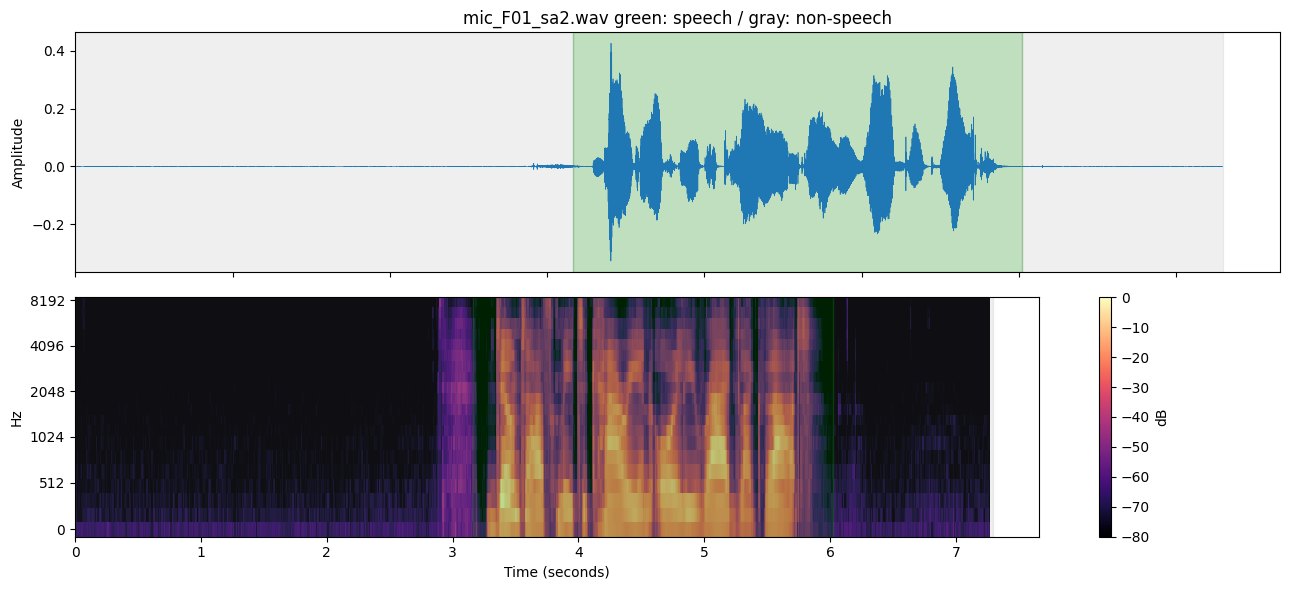

In [16]:
# process and display example wav file:
exampleWAV = process_file(wav_files[0], input_root, visualize=True)

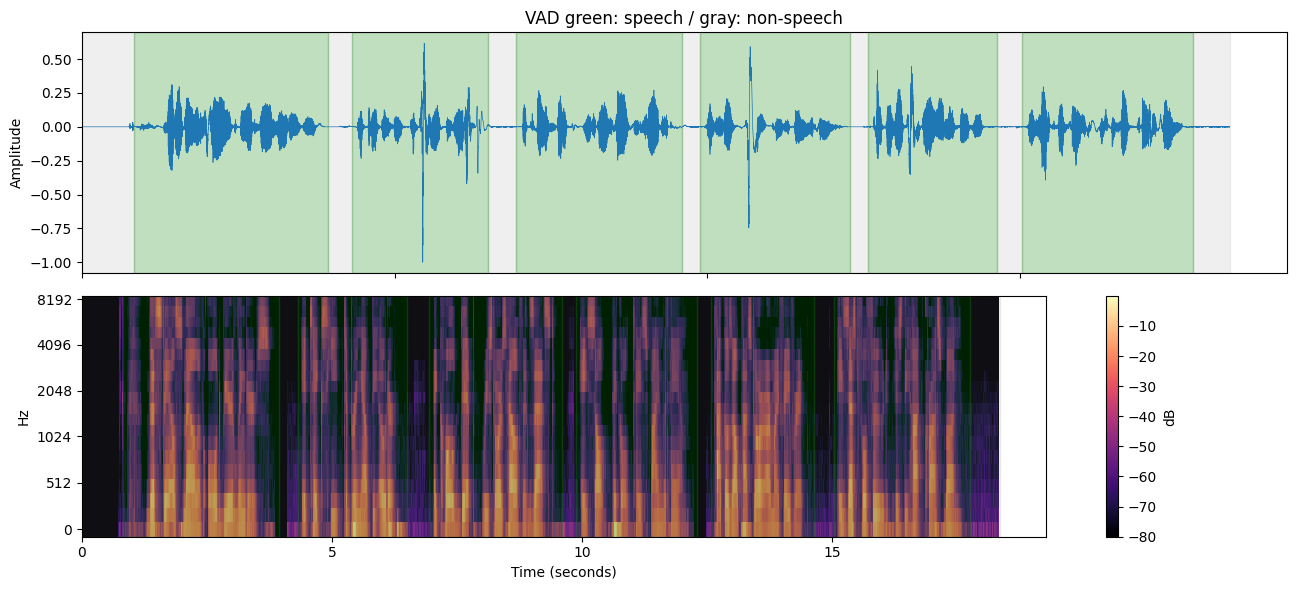

Speech regions detected: 6 at sample: [(13248, 63040), (69056, 104000), (111040, 153664), (158144, 196672), (201152, 234048), (240576, 284224)]


In [17]:
# process and display example wav file:
y, sr, feats = load_and_extract(EXAMPLE_WAV_FILE)
speech_intervals, nonspeech_intervals = detect_regions(y, sr)
plot_vad(y, sr, feats, speech_intervals, nonspeech_intervals)
print(f"Speech regions detected: {len(speech_intervals)} at sample: {speech_intervals}")

# ipd.Audio(EXAMPLE_WAV_FILE)

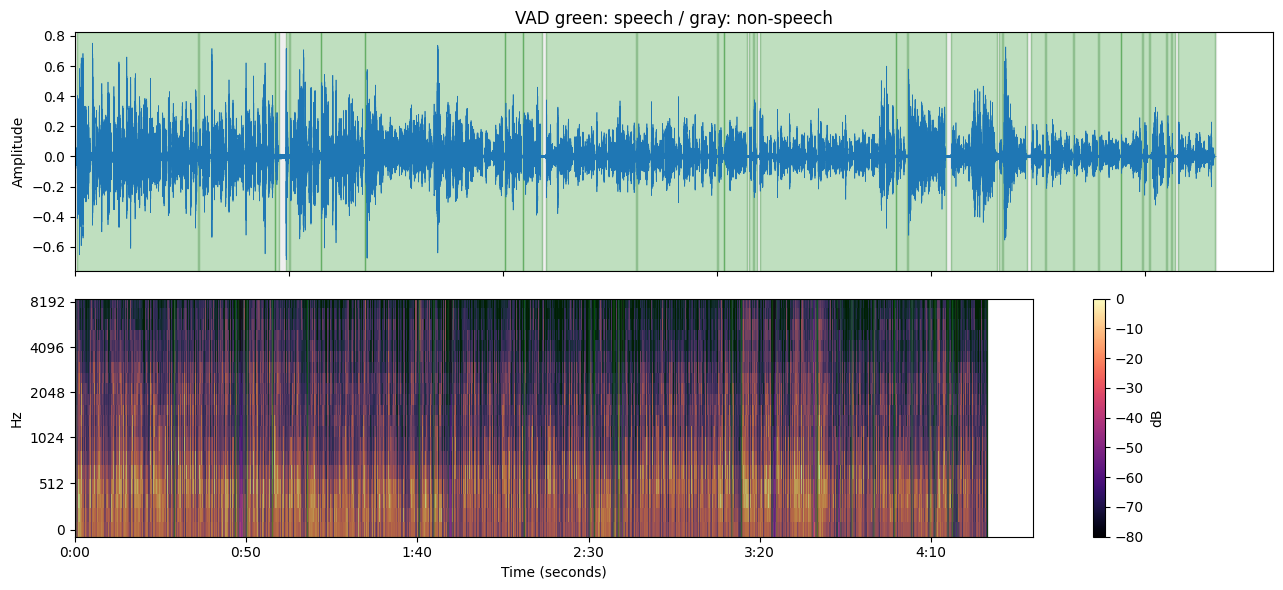

Speech regions detected: 31 at sample: [(7616, 461888), (462784, 747584), (750016, 763456), (787904, 800320), (804800, 919616), (920512, 1082944), (1085888, 1607232), (1608640, 1674304), (1676736, 1744448), (1760704, 2098752), (2099648, 2401856), (2405312, 2426432), (2427840, 2512960), (2519488, 2535488), (2536384, 2550848), (2559424, 3067456), (3069888, 3110464), (3112896, 3255360), (3274176, 3445312), (3455424, 3466304), (3467712, 3560000), (3572672, 3625536), (3628480, 3729984), (3732416, 3824704), (3826624, 3908160), (3909568, 3989568), (3992512, 4012608), (4018112, 4076096), (4081088, 4097088), (4098496, 4109888), (4122048, 4260416)]


In [18]:
# process and display example mp3 file:
y, sr, feats = load_and_extract(EXAMPLE_MP3_FILE)
speech_intervals, nonspeech_intervals = detect_regions(y, sr)
plot_vad(y, sr, feats, speech_intervals, nonspeech_intervals)
print(f"Speech regions detected: {len(speech_intervals)} at sample: {speech_intervals}")

# ipd.Audio(EXAMPLE_MP3_FILE)

### Offene Fragen
- Wie abspeichern
- Implementierung eines Streams zum Einlesen & Verarbeiten der Audiodateien
- Wann & wo ML-Modelle einsetzen
- Aussehen der finalen Anwendung (desktop, web oder ipynb)
- Umgang mit erfassung gleichzeitiger sprecher
  - Insbesondere mit Überlappungen
- Real-time?
-

#### Annahmen
- DER Grenzwert?
- RTF Wert
